# NeurIPS 2021 BMMC multiome (all 13 samples): preprocessing, clustering and annotation

Bone marrow mononuclear cells from all 13 multiome samples of GSE194122 (Luecken et al.): 10 donors measured at
4 sites, some donors at several sites (donor 1 at sites 1, 2 and 4; donor 3 at sites 1 and 3). They are processed
exactly as `pbmc_v3.ipynb` and `bmmc_s1d1_s1d3_v3.ipynb`, so models trained on the PBMC data can be tested on them. The
inputs are:

- **GEX:** the Cell Ranger ARC `filtered_feature_bc_matrix.h5` rebuilt from each sample's GEX BAM, because no
  multiome `.h5` is public (`jobs/06_rebuild_gex.sbatch`). The rebuild reproduces our PBMC `.h5` exactly, and
  every sample's per-cell totals match Cell Ranger's `per_barcode_metrics.csv` exactly.
- **ATAC:** Cell Ranger ARC's own fragment files (S3).
- **Combination:** the 13 samples combined `aggr`-style (`jobs/07_bmmc_aggr.sbatch`), with barcode suffixes
  `-1` ... `-13` in the order of `metadata/bmmc_samples.tsv` (s1d1, s1d2, s1d3, s2d1, s2d4, s2d5, s3d3, s3d6,
  s3d7, s3d10, s4d1, s4d8, s4d9). Each cell's `sample`, `site` and `donor` come from that table.

Differences from `pbmc_v3`, all because there are several samples or no peak matrix:

- Scrublet runs per sample, with each sample's own expected doublet rate.
- AMULET is read per GEM well (`batch_1` ... `batch_13`).
- No ATAC peak matrix is public, so only `rna_annotated.h5ad` is saved; ATAC analyses use the fragment files instead.

There is no batch integration. Leiden clusters and UMAPs may split partly by site; they are only used to judge
QC, so read them alongside the sample and site UMAPs. Azimuth maps each cell to the reference on its own, so the
cell-type labels don't depend on the clustering.

**Resources:** about 130,000 called cells, ten times `bmmc_s1d1_s1d3`. Azimuth, the largest step, runs as a separate
batch job (`jobs/08_azimuth.sbatch`); the notebook itself peaks at about 15 GB of RAM.

---

The rest follows `pbmc_v3`.

Follows the scanpy [preprocessing and clustering tutorial](https://scanpy.readthedocs.io/en/stable/tutorials/basics/clustering.html),
with ATAC quality control added: fragment counts, TSS enrichment (TSSE), nucleosome signal
and AMULET multiplets. A cell is kept only if it passes both the RNA and the ATAC checks.

**Pipeline**

1. QC metrics for both modalities.
2. **Light filter:** remove barcodes that aren't usable cells (fewer than 100 genes or 1,000 ATAC
   fragments), then genes detected in fewer than 3 cells.
3. **Doublet detection** (Scrublet and AMULET): cells are flagged, not yet removed.
4. **Exploratory clustering** of the light-filtered cells.
5. **Re-assess QC** on those clusters.
6. **First filtering:** remove low-quality cells and doublets, with no upper limits on RNA counts or
   ATAC fragments (very high values are left to the doublet detectors). Re-plot QC and re-cluster the
   remaining cells, then **final filtering** adds upper limits on RNA counts and ATAC fragments to remove
   remaining potential doublets, and drops genes detected in fewer than 3 of the final cells.
7. **Final clustering** of the filtered cells, then **cell-type annotation with Azimuth**.

Doublet scores depend only on the fixed light filter, so the thresholds in step 6 can be changed without
redoing doublet detection.

In [1]:
import collections
import os
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.collections import PathCollection
from matplotlib.figure import Figure

# rpy2 finds R through R_HOME, which the Jupyter kernel doesn't set (it doesn't activate the env)
os.environ.setdefault("R_HOME", os.path.join(sys.prefix, "lib", "R"))
from azimuthpy import annotate_adata_azimuth  # loads Seurat and Azimuth in R

sc.set_figure_params(dpi=300, facecolor="white")
# every figure shown is also saved to figures/<notebook>/<In[] number>_<n>_<title>.svg; point clouds are
# rasterised at 300 dpi inside it, text and axes stay vector (and text editable)
svg_dir = Path.cwd().parent / "figures" / "bmmc_all_v3"
svg_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams["svg.fonttype"] = "none"
png_formatter = get_ipython().display_formatter.formatters["image/png"]
show_png = png_formatter.lookup_by_type(Figure)
figs_in_cell = collections.Counter()


def save_svg_and_show(fig):
    cell = get_ipython().execution_count
    figs_in_cell[cell] += 1
    labels = [ax.get_title() or ax.get_ylabel() for ax in fig.axes]
    title = re.sub(r"\W+", "_", next((label for label in labels if label), "figure")).strip("_")[:40]
    for points in fig.findobj(PathCollection):
        if len(points.get_offsets()) > 1000:
            points.set_rasterized(True)
    fig.savefig(svg_dir / f"{cell:03d}_{figs_in_cell[cell]}_{title}.svg", dpi=300, bbox_inches="tight")
    return show_png(fig)


png_formatter.for_type(Figure, save_svg_and_show)

ROOT = Path.cwd().parent
DATA = ROOT / "data"
SAMPLE = "bmmc_all"
# GEM-well suffix -> sample, site and donor, in the order jobs/07_bmmc_aggr.sbatch combined them
samples = pd.read_csv(ROOT / "metadata" / "bmmc_samples.tsv", sep="\t", dtype=str)
samples.index = (np.arange(len(samples)) + 1).astype(str)
assert len(samples) == 13 and samples["sample"].is_unique
h5_file = DATA / "raw" / SAMPLE / f"{SAMPLE}_filtered_feature_bc_matrix.h5"  # data/raw/bmmc_all links to scratch
atac_metrics_file = DATA / "processed" / SAMPLE / "atac_metrics.tsv"
amulet_files = [DATA / "processed" / SAMPLE / "amulet" / f"batch_{well}" / "MultipletProbabilities.txt"
                for well in samples.index]
out_dir = DATA / "processed" / SAMPLE
azimuth_ref = DATA / "reference" / "azimuth" / "human_pbmc"
# clustered.h5ad (before annotation) and azimuth.h5ad (jobs/08_azimuth.sbatch); scratch, not the home quota
work_dir = DATA / "scratch" / "processed" / SAMPLE
work_dir.mkdir(parents=True, exist_ok=True)
samples[["sample", "site", "donor"]]


    an issue that caused a segfault when used with rpy2:
    https://github.com/rstudio/reticulate/pull/1188
    Make sure that you use a version of that package that includes
    the fix.
    

,sample,site,donor
1,s1d1,1,1
2,s1d2,1,2
3,s1d3,1,3
4,s2d1,2,1
5,s2d4,2,4
6,s2d5,2,5
7,s3d3,3,3
8,s3d6,3,6
9,s3d7,3,7
10,s3d10,3,10


## Data loading

The rebuilt file holds gene expression only (no peaks). Each cell's sample, site and donor come from its barcode suffix.

In [2]:
adata = sc.read_10x_h5(h5_file)
adata.var_names_make_unique()
well = adata.obs_names.str.rsplit("-", n=1).str[1]
assert well.isin(samples.index).all()
for col in ["sample", "site", "donor"]:
    # samples in table order; sites and donors in numeric order
    order = samples[col].drop_duplicates() if col == "sample" else sorted(samples[col].unique(), key=int)
    adata.obs[col] = pd.Categorical(well.map(samples[col]), categories=order)

# Cell Ranger-called cells per sample, before the light filter: sets each sample's expected doublet rate below
n_called = adata.obs["sample"].value_counts()
print(n_called.to_string())
adata

/gpfs/scratch/qp252877/anaconda/envs/azimuth/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


/gpfs/scratch/qp252877/anaconda/envs/azimuth/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


sample
s3d3     18877
s3d10    17598
s4d8     16934
s4d1     16337
s2d4     10062
s1d1      8442
s1d2      8341
s2d5      8246
s4d9      8217
s2d1      6319
s1d3      5626
s3d7      2740
s3d6      2355


AnnData object with n_obs × n_vars = 130094 × 36601
    obs: 'sample', 'site', 'donor'
    var: 'gene_ids', 'feature_types', 'genome', 'interval'

## Quality control metrics

### RNA

In [3]:
# mitochondrial genes, "MT-" for human
adata.var["mt"] = adata.var_names.str.startswith("MT-")
# ribosomal genes
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True)

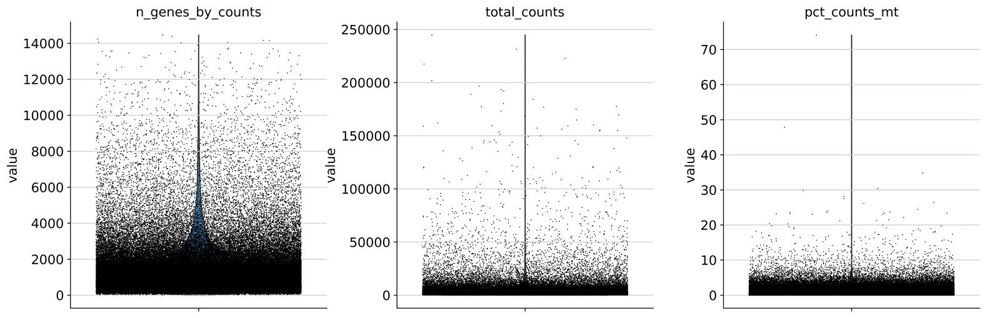

In [4]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

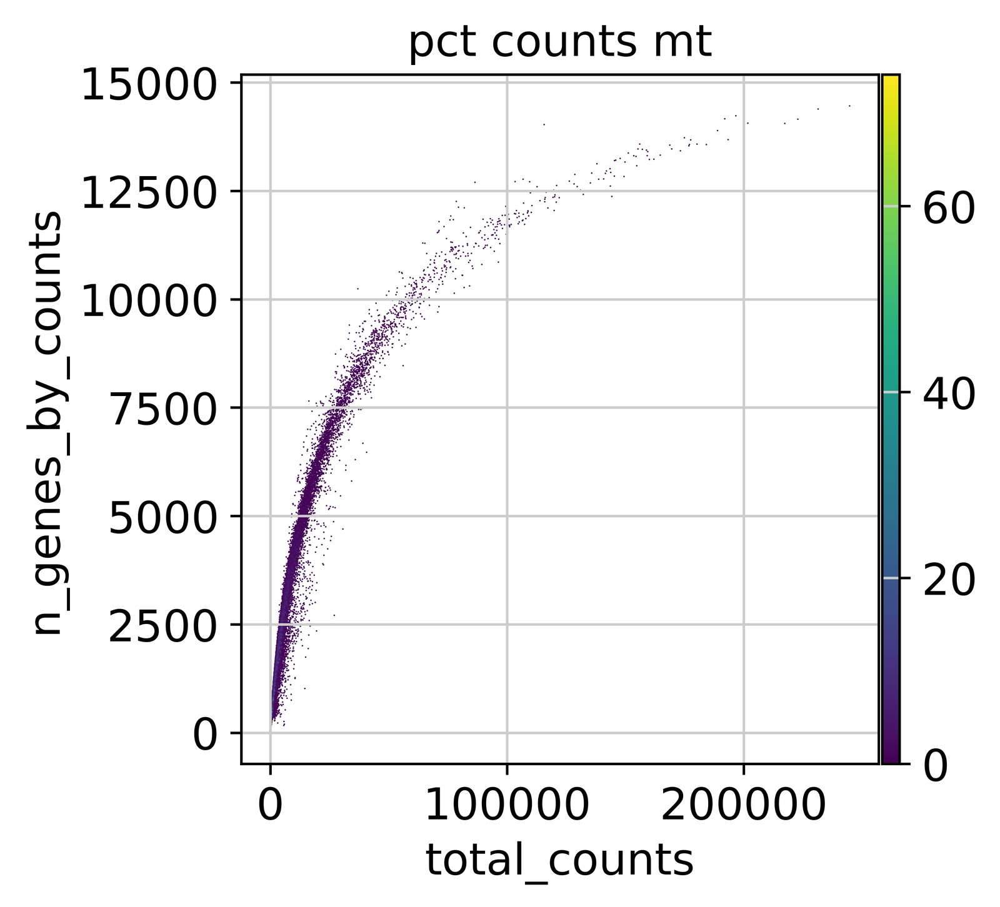

In [5]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

### ATAC

SnapATAC2 reads each cell's fragments from the fragment file, counts them (`n_fragment`) and
computes TSS enrichment (`tsse`). It has no per-cell nucleosome signal, so we compute it as
Signac does: fragments of 147-294 bp (one nucleosome) divided by fragments under 147 bp
(nucleosome-free).

Reading the fragment file takes several minutes, so these metrics are computed once by
`jobs/04_atac_metrics.sbatch` and saved to `atac_metrics.tsv`; this cell loads them.

In [6]:
# computed by jobs/04_atac_metrics.sbatch
atac_metrics = pd.read_csv(atac_metrics_file, sep="\t", index_col="barcode")
adata.obs = adata.obs.join(atac_metrics[["n_fragment", "tsse", "nucleosome_signal"]])
adata.obs["log1p_n_fragment"] = np.log1p(adata.obs["n_fragment"])
print(adata.obs["n_fragment"].isna().sum(), "cells without ATAC metrics")

0 cells without ATAC metrics


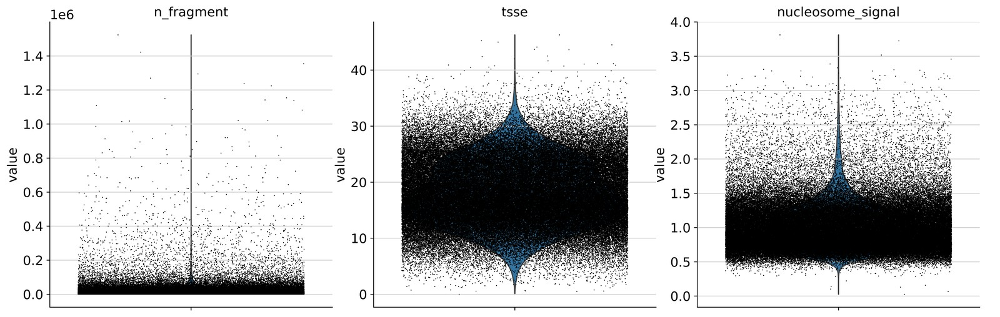

In [7]:
sc.pl.violin(
    adata,
    ["n_fragment", "tsse", "nucleosome_signal"],
    jitter=0.4,
    multi_panel=True,
)

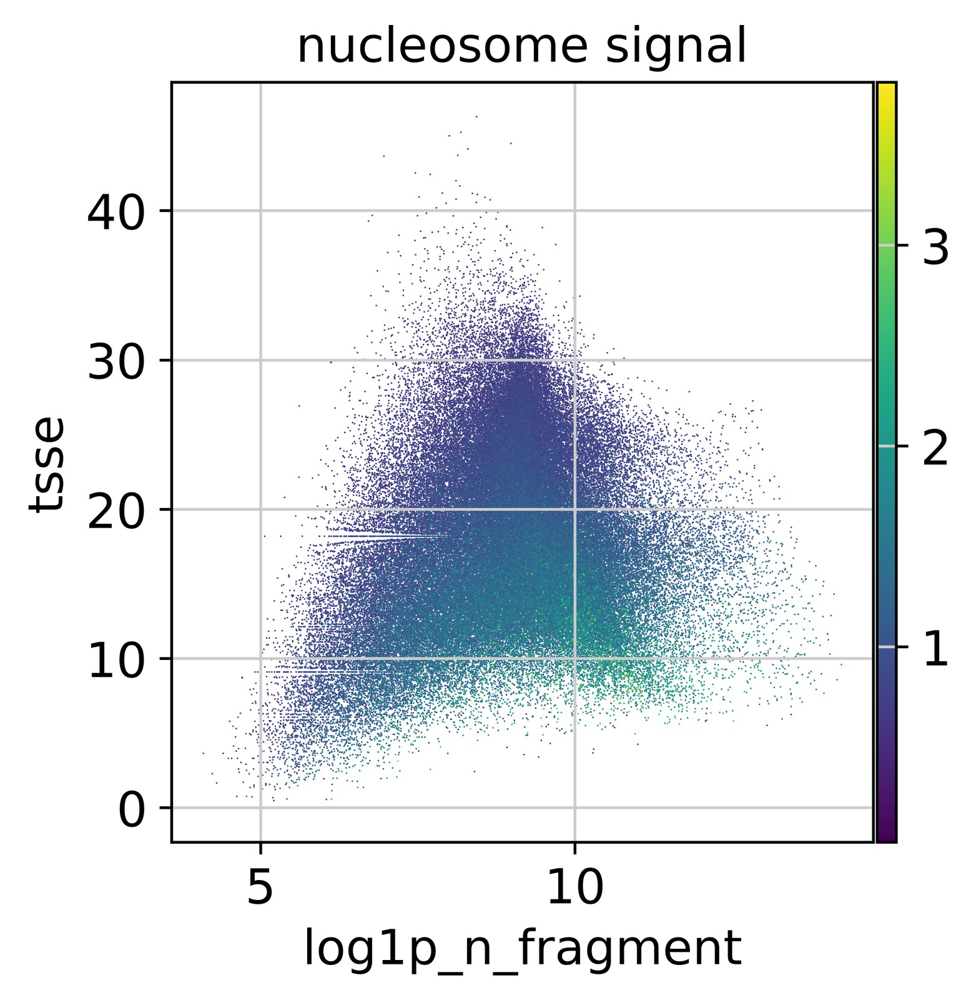

In [8]:
sc.pl.scatter(adata, "log1p_n_fragment", "tsse", color="nucleosome_signal")

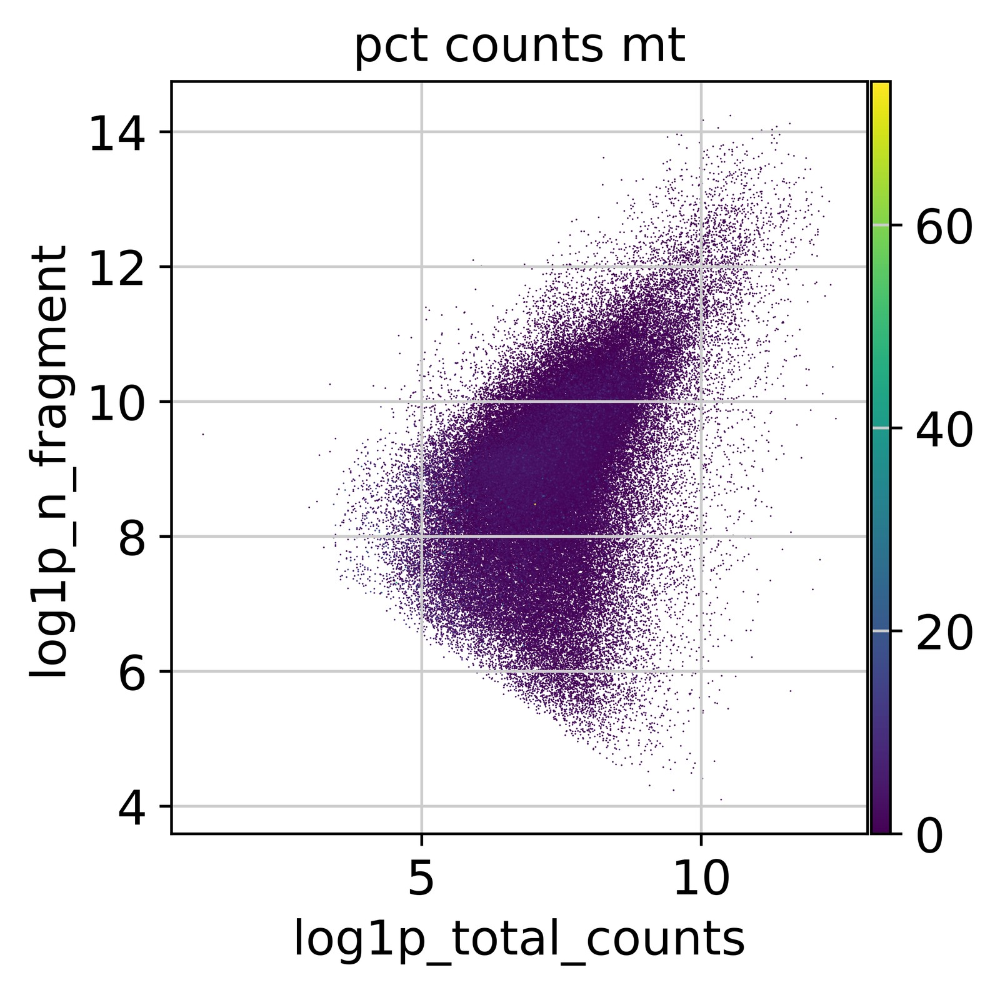

In [9]:
sc.pl.scatter(adata, "log1p_total_counts", "log1p_n_fragment", color="pct_counts_mt")

## Light filter

Removes barcodes that aren't usable cells in either modality: fewer than 100 genes (RNA) or fewer than
1,000 ATAC fragments. Then removes genes detected in fewer than 3 cells, as in the tutorial.

These are fixed floors, not thresholds to tune: doublet detection runs on the cells that remain, so
changing them would change the doublet scores. The thresholds to tune come later, in **First filtering** and **Final filtering**.

In [10]:
light = (adata.obs["n_genes_by_counts"] >= 100) & (adata.obs["n_fragment"] >= 1_000)
print(f"Light filter keeps {light.sum()} of {len(light)} cells ({(~light).mean():.1%} removed)")

adata = adata[light].copy()
sc.pp.filter_genes(adata, min_cells=3)

# Saving count data
adata.layers["counts"] = adata.X.copy()
adata

Light filter keeps 120807 of 130094 cells (7.1% removed)


AnnData object with n_obs × n_vars = 120807 × 33706
    obs: 'sample', 'site', 'donor', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_fragment', 'tsse', 'nucleosome_signal', 'log1p_n_fragment'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: 'counts'

## Doublet detection

Two independent calls, one per modality:

- **Scrublet** (RNA) compares each cell with simulated doublets.
- **AMULET** (ATAC) flags cells with more loci covered by more than two reads than a single
  diploid nucleus should have. It was run by `jobs/03_amulet.sbatch`; here we read its q-values.

Cells are only **flagged** here. They are removed in **First filtering**, together with the QC checks, so the
preview there shows QC failures and doublets side by side.

AMULET was run on all Cell Ranger-called cells, before QC, which is how its documentation intends it
to be used (its input is Cell Ranger's list of called cells). Re-running it on QC-passing cells only
was tested: it flagged every cell the current run flags plus another 150-220 per dataset, pushing
doublet rates well above 10x's expected rates, so the current approach was kept.

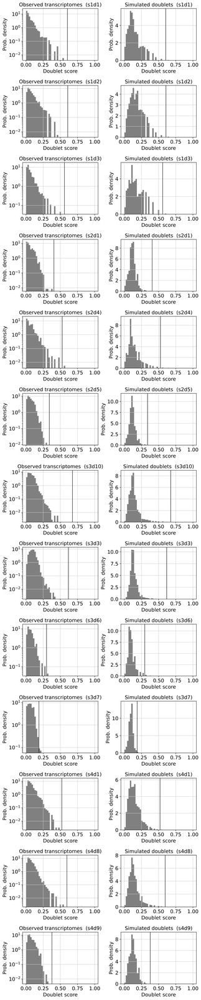

In [11]:
sc.pp.scrublet(adata, batch_key="sample")  # simulated doublets only within a sample
# the vertical lines are Scrublet's automatic thresholds, which are not used (see below)
sc.pl.scrublet_score_distribution(adata)

Scrublet's automatic threshold doesn't suit this dataset, so the threshold is set from 10x Genomics'
expected doublet rate instead.

**Rule:** separately per sample, flag the top X% of Scrublet scores. X is 10x's expected doublet rate of about
0.8% per 1,000 cells recovered, i.e. that sample's Cell Ranger-called cells:
the 13 samples have 2,355 (s3d6) to 18,877 (s3d3) called cells, so 1.9% to 15.1%.

It prints each sample's score quantiles, threshold and flagged rate.

In [12]:
adata.obs["predicted_doublet"] = False
for sample, n in n_called.items():
    in_sample = adata.obs["sample"] == sample
    scores = adata.obs.loc[in_sample, "doublet_score"]
    # 10x guideline: ~0.8% doublets per 1,000 cells recovered
    expected_rate = 0.008 * n / 1000
    # flag the top expected_rate of scores; >= so cells tied at the threshold are flagged too
    threshold = scores.quantile(1 - expected_rate)
    adata.obs.loc[in_sample, "predicted_doublet"] = scores >= threshold
    print(f"{sample}: score quantiles {scores.quantile([0.90, 0.95, 0.98, 0.99]).round(3).tolist()}; "
          f"expected rate {expected_rate:.1%} -> threshold {threshold:.3f}, "
          f"flags {(scores >= threshold).sum()} cells ({(scores >= threshold).mean():.1%})")

s3d3: score quantiles [0.146, 0.164, 0.186, 0.203]; expected rate 15.1% -> threshold 0.132, flags 3154 cells (17.5%)
s3d10: score quantiles [0.132, 0.159, 0.189, 0.218]; expected rate 14.1% -> threshold 0.124, flags 2476 cells (14.7%)
s4d8: score quantiles [0.136, 0.159, 0.199, 0.246]; expected rate 13.5% -> threshold 0.122, flags 2150 cells (14.1%)
s4d1: score quantiles [0.139, 0.17, 0.218, 0.258]; expected rate 13.1% -> threshold 0.124, flags 2102 cells (14.1%)
s2d4: score quantiles [0.126, 0.163, 0.208, 0.24]; expected rate 8.0% -> threshold 0.139, flags 731 cells (8.3%)
s1d1: score quantiles [0.121, 0.157, 0.232, 0.272]; expected rate 6.8% -> threshold 0.140, flags 610 cells (7.5%)
s1d2: score quantiles [0.157, 0.201, 0.25, 0.298]; expected rate 6.7% -> threshold 0.188, flags 581 cells (7.3%)
s2d5: score quantiles [0.127, 0.142, 0.169, 0.193]; expected rate 6.6% -> threshold 0.134, flags 649 cells (8.7%)
s4d9: score quantiles [0.142, 0.159, 0.193, 0.207]; expected rate 6.6% -> thre

In [13]:
amulet = pd.concat([pd.read_csv(f, sep="\t", index_col="barcode") for f in amulet_files])
adata.obs["amulet_q"] = amulet["q-value"].reindex(adata.obs_names)
adata.obs["amulet_multiplet"] = adata.obs["amulet_q"] < 0.01
print(adata.obs.groupby("sample", observed=True)["amulet_multiplet"].agg(["sum", "mean"]).round(3).to_string())

pd.crosstab(adata.obs["predicted_doublet"], adata.obs["amulet_multiplet"])

         sum   mean
sample             
s1d1     351  0.043
s1d2     327  0.041
s1d3     299  0.055
s2d1     229  0.040
s2d4     406  0.046
s2d5     298  0.040
s3d10    892  0.053
s3d3     633  0.035
s3d6     145  0.064
s3d7     232  0.085
s4d1    1160  0.078
s4d8    1301  0.085
s4d9     461  0.063


amulet_multiplet,False,True
predicted_doublet,,
False,102192,4877
True,11881,1857


In [14]:
# one label per cell for plotting
adata.obs["doublet"] = pd.Categorical(
    np.select(
        [adata.obs["predicted_doublet"] & adata.obs["amulet_multiplet"],
         adata.obs["predicted_doublet"],
         adata.obs["amulet_multiplet"]],
        ["both", "Scrublet", "AMULET"],
        default="none",
    ),
    categories=["none", "Scrublet", "AMULET", "both"],
)
adata.obs["doublet"].value_counts()

doublet
none        102192
Scrublet     11881
AMULET        4877
both          1857
Name: count, dtype: int64

## Exploratory clustering

Normalise, select highly variable genes, PCA, neighbours, UMAP and Leiden on the light-filtered cells,
as in the tutorial. These clusters are only used to judge QC; everything is redone on the final cells
after filtering. The steps are written once as a function, used here and again in **Final clustering**.

In [15]:
def normalise_and_cluster(adata, batch_key=None):
    """Normalise, log1p, HVGs, PCA, kNN graph, UMAP and Leiden, starting from the raw counts."""
    adata.X = adata.layers["counts"].copy()
    adata.uns.pop("log1p", None)
    sc.pp.normalize_total(adata)
    sc.pp.log1p(adata)
    sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key=batch_key)
    sc.tl.pca(adata)
    sc.pp.neighbors(adata)
    sc.tl.umap(adata)
    sc.tl.leiden(adata, flavor="igraph", n_iterations=2)


normalise_and_cluster(adata)

/gpfs/scratch/qp252877/anaconda/envs/azimuth/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


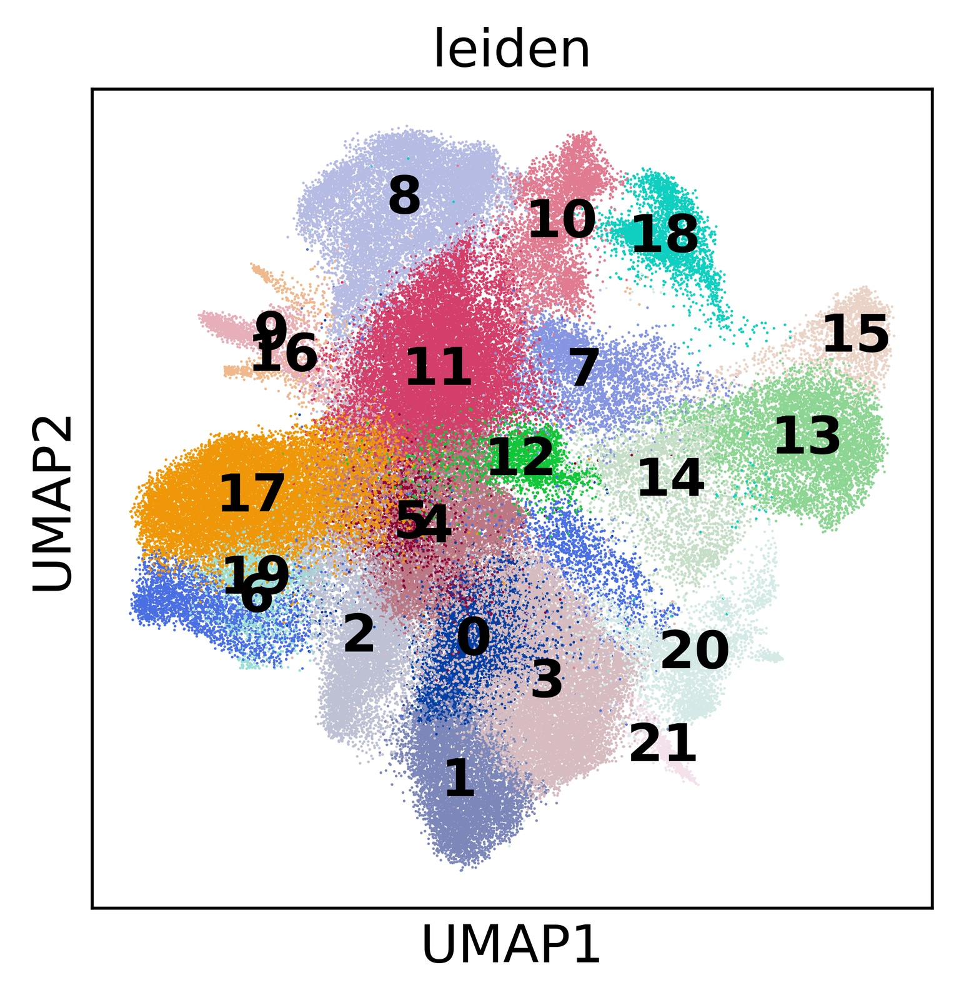

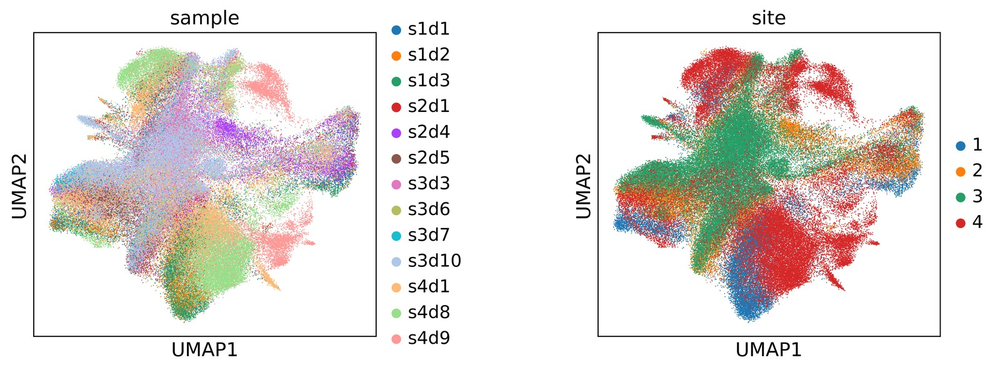

In [16]:
sc.pl.umap(adata, color="leiden", legend_loc="on data", size=2)
sc.pl.umap(adata, color=["sample", "site"], wspace=0.5, size=2)

## Re-assess QC on the exploratory clusters

Look at where low-quality cells and doublets sit on the exploratory clusters:

- **Cells failing a check form their own cluster** with no clear marker genes: a technical artefact,
  so remove them.
- **They are scattered through normal clusters:** the threshold may be too strict, removing healthy cells.
- **They are concentrated in one biological cell type:** the threshold is biased against that type (some
  cell types naturally have lower TSSE or more mito or RNA), so consider relaxing it.

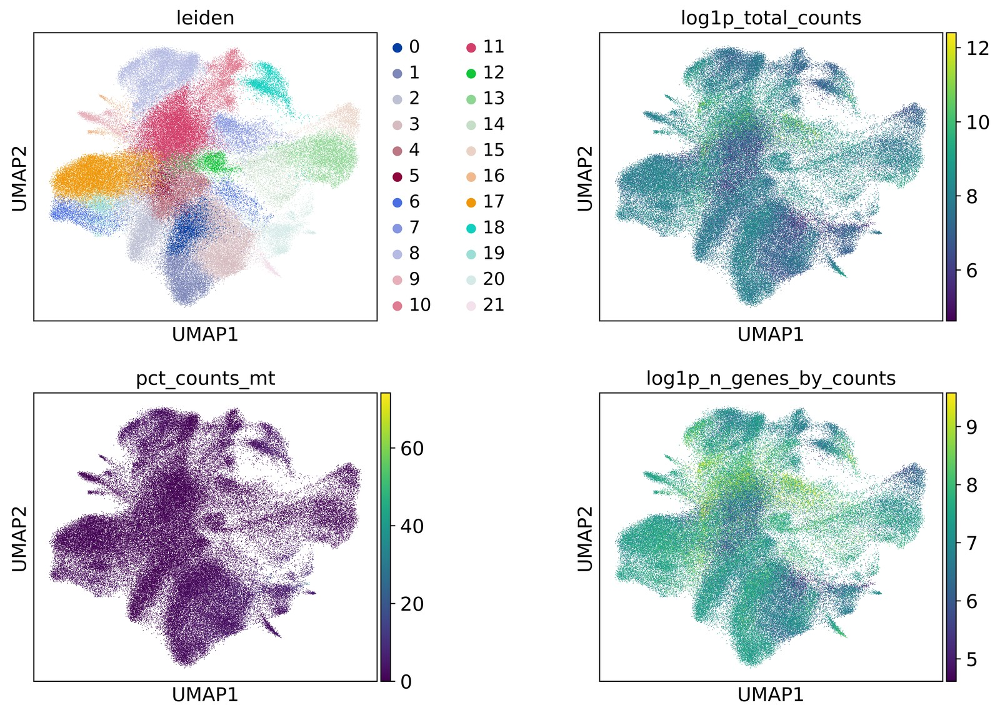

In [17]:
sc.pl.umap(
    adata,
    color=["leiden", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts"],
    wspace=0.5,
    ncols=2,
)

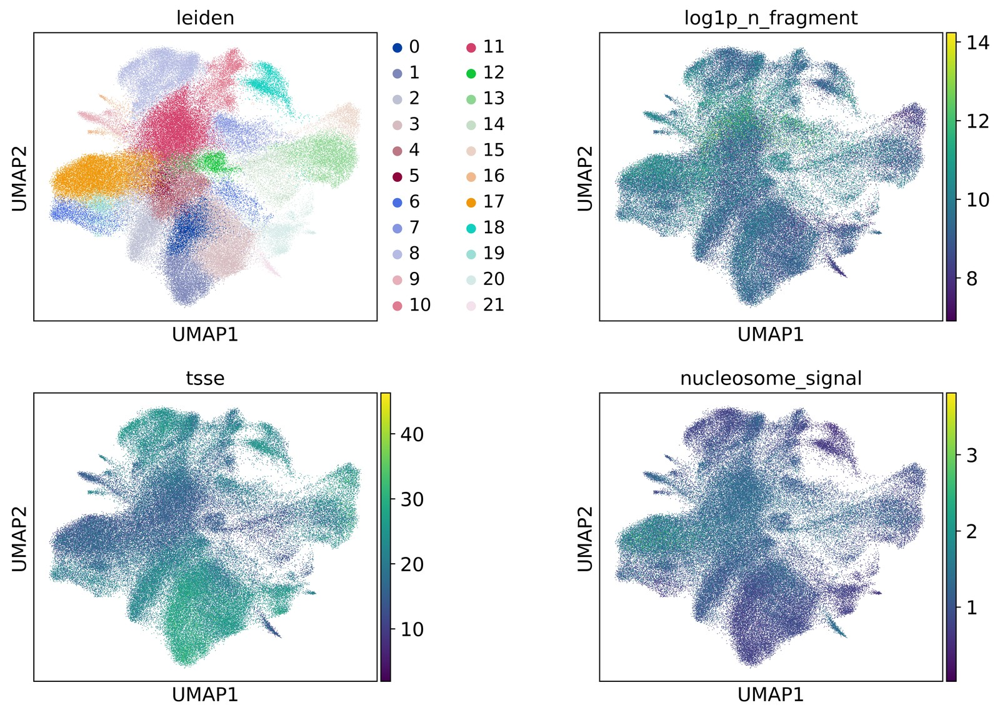

In [18]:
sc.pl.umap(
    adata,
    color=["leiden", "log1p_n_fragment", "tsse", "nucleosome_signal"],
    wspace=0.5,
    ncols=2,
)

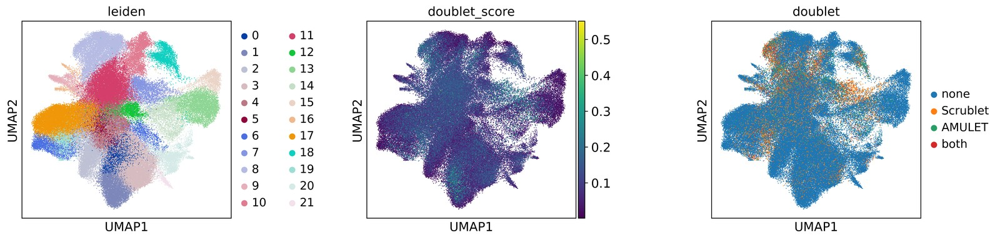

In [19]:
sc.pl.umap(
    adata,
    color=["leiden", "doublet_score", "doublet"],
    wspace=0.5,
    size=3,
)

In [20]:
# # cluster markers, to judge whether a cluster is biology or an artefact
# sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")
# sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden", standard_scale="var", n_genes=4)

### First filtering: low-quality cells and doublets

Removes low-quality cells and the cells flagged by Scrublet or AMULET. There are no upper limits on RNA
counts or ATAC fragments yet: very high values are often doublets, which the two detectors are meant to
catch, so this step leaves them to Scrublet and AMULET. The gene minimum stays at the light filter's 100,
and the ATAC fragment minimum (1,000) is already enforced by the light filter.

The first cell only previews: it reports how many cells each check would remove and, per exploratory
cluster, the share failing each check. Re-run it as you adjust the numbers, then apply.

In [21]:
checks = pd.DataFrame({
    "RNA: genes >= 100": adata.obs["n_genes_by_counts"] >= 100,
    "RNA: counts >= 500": adata.obs["total_counts"] >= 500,
    "RNA: mito <= 10%": adata.obs["pct_counts_mt"] <= 10,
    "ATAC: TSSE >= 5": adata.obs["tsse"] >= 5,
    "ATAC: nucleosome signal < 2": adata.obs["nucleosome_signal"] < 2,
    "Doublet: Scrublet": ~adata.obs["predicted_doublet"],
    "Doublet: AMULET": ~adata.obs["amulet_multiplet"],
})

summary = pd.DataFrame({
    "fail": (~checks).sum(),
    "fail only this check": {c: (~checks[c] & checks.drop(columns=c).all(axis=1)).sum() for c in checks},
})
print(summary.to_string())

keep = checks.all(axis=1)
print(f"\nWould remove {(~keep).sum()} of {len(keep)} cells ({(~keep).mean():.1%}), keeping {keep.sum()}")

adata.obs["qc"] = pd.Categorical(np.where(keep, "keep", "remove"))
print(pd.crosstab(adata.obs["sample"], adata.obs["qc"]).to_string())
print(pd.crosstab(adata.obs["site"], adata.obs["qc"]).to_string())

                              fail  fail only this check
RNA: genes >= 100                0                     0
RNA: counts >= 500           14828                 13505
RNA: mito <= 10%               230                    50
ATAC: TSSE >= 5                 93                    49
ATAC: nucleosome signal < 2   2034                  1652
Doublet: Scrublet            13738                 10661
Doublet: AMULET               6734                  4792

Would remove 34171 of 120807 cells (28.3%), keeping 86636
qc       keep  remove
sample               
s1d1     6972    1159
s1d2     6788    1196
s1d3     4729     673
s2d1     4664    1023
s2d4     7338    1508
s2d5     6057    1421
s3d3     9976    8017
s3d6     1974     293
s3d7     2194     522
s3d10   11484    5380
s4d1     9430    5441
s4d8    10134    5095
s4d9     4896    2443
qc     keep  remove
site               
1     18489    3028
2     18059    3952
3     25628   14212
4     24460   12979


In [22]:
# share of each exploratory cluster failing each check
by_cluster = (~checks).groupby(adata.obs["leiden"], observed=True).mean().round(2)
by_cluster.insert(0, "cells", adata.obs["leiden"].value_counts())
by_cluster

,cells,RNA: genes >= 100,RNA: counts >= 500,RNA: mito <= 10%,ATAC: TSSE >= 5,ATAC: nucleosome signal < 2,Doublet: Scrublet,Doublet: AMULET
leiden,,,,,,,,
0,6441,0.0,0.06,0.00,0.0,0.00,0.05,0.03
1,6959,0.0,0.05,0.00,0.0,0.00,0.07,0.01
2,7345,0.0,0.07,0.00,0.0,0.01,0.11,0.04
3,13095,0.0,0.26,0.00,0.0,0.00,0.09,0.03
4,8729,0.0,0.18,0.00,0.0,0.01,0.09,0.02
5,1711,0.0,0.73,0.00,0.0,0.01,0.08,0.00
6,3986,0.0,0.03,0.01,0.0,0.04,0.12,0.06
7,3325,0.0,0.03,0.00,0.0,0.01,0.27,0.21
8,10918,0.0,0.04,0.00,0.0,0.00,0.17,0.13


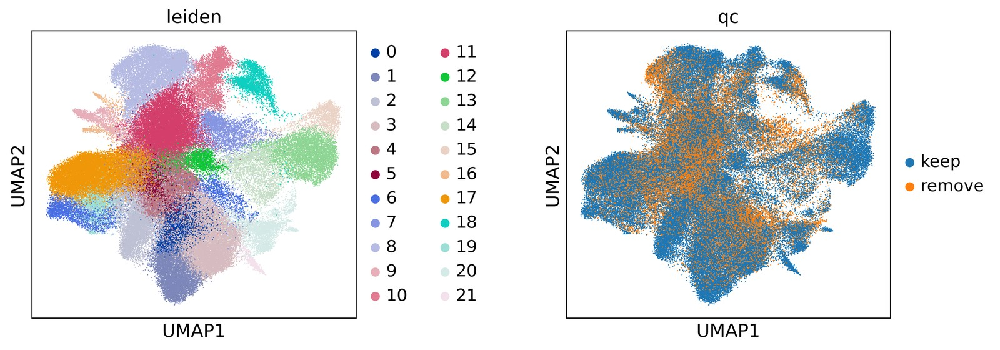

In [23]:
sc.pl.umap(adata, color=["leiden", "qc"], wspace=0.5, size=3)

### Apply the first filter

In [24]:
adata = adata[keep].copy()
adata

AnnData object with n_obs × n_vars = 86636 × 33706
    obs: 'sample', 'site', 'donor', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_fragment', 'tsse', 'nucleosome_signal', 'log1p_n_fragment', 'n_genes', 'doublet_score', 'predicted_doublet', 'amulet_q', 'amulet_multiplet', 'doublet', 'leiden', 'qc'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden

## Re-assess QC after the first filtering

The same QC plots and UMAPs as before, now on the cells that remain, re-clustered without the removed
cells. Any doublets the detectors missed should stand out as cells with very high RNA counts or ATAC
fragments, often forming their own small clusters or sitting between cell types. Use these plots to
choose the upper limits in **Final filtering**.

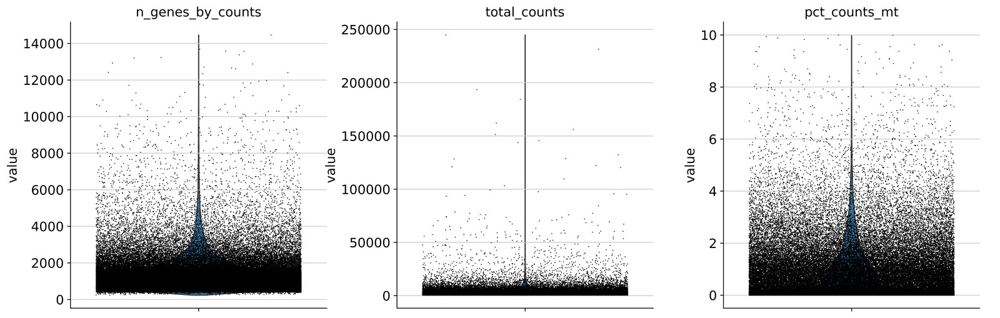

In [25]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

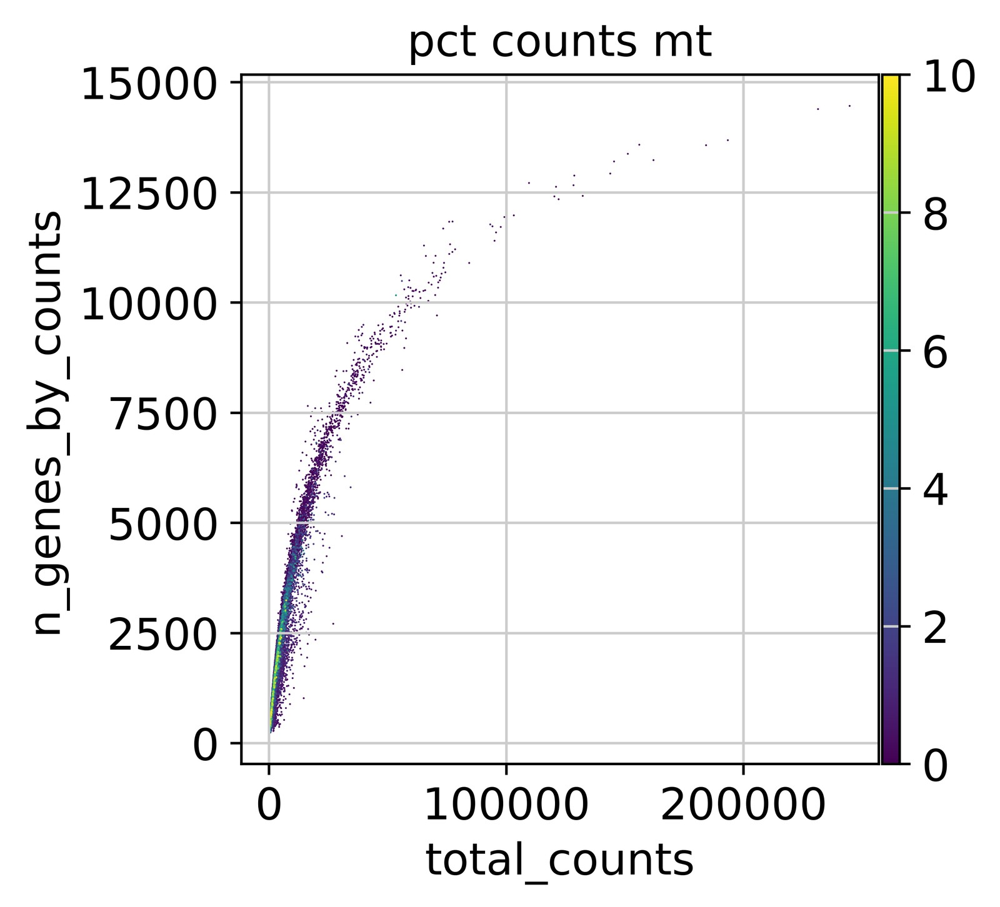

In [26]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

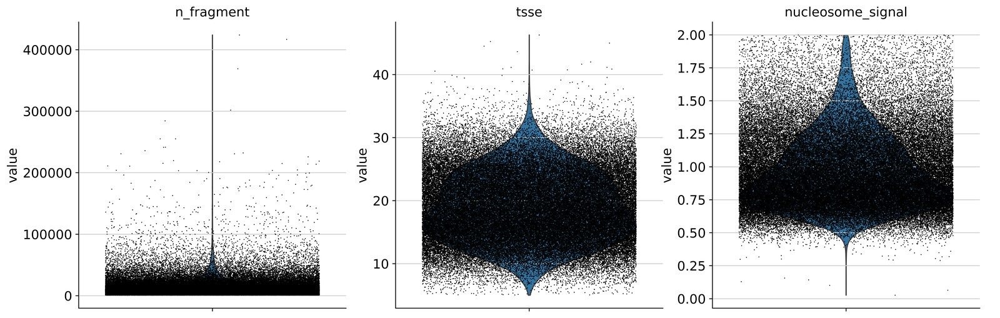

In [27]:
sc.pl.violin(
    adata,
    ["n_fragment", "tsse", "nucleosome_signal"],
    jitter=0.4,
    multi_panel=True,
)

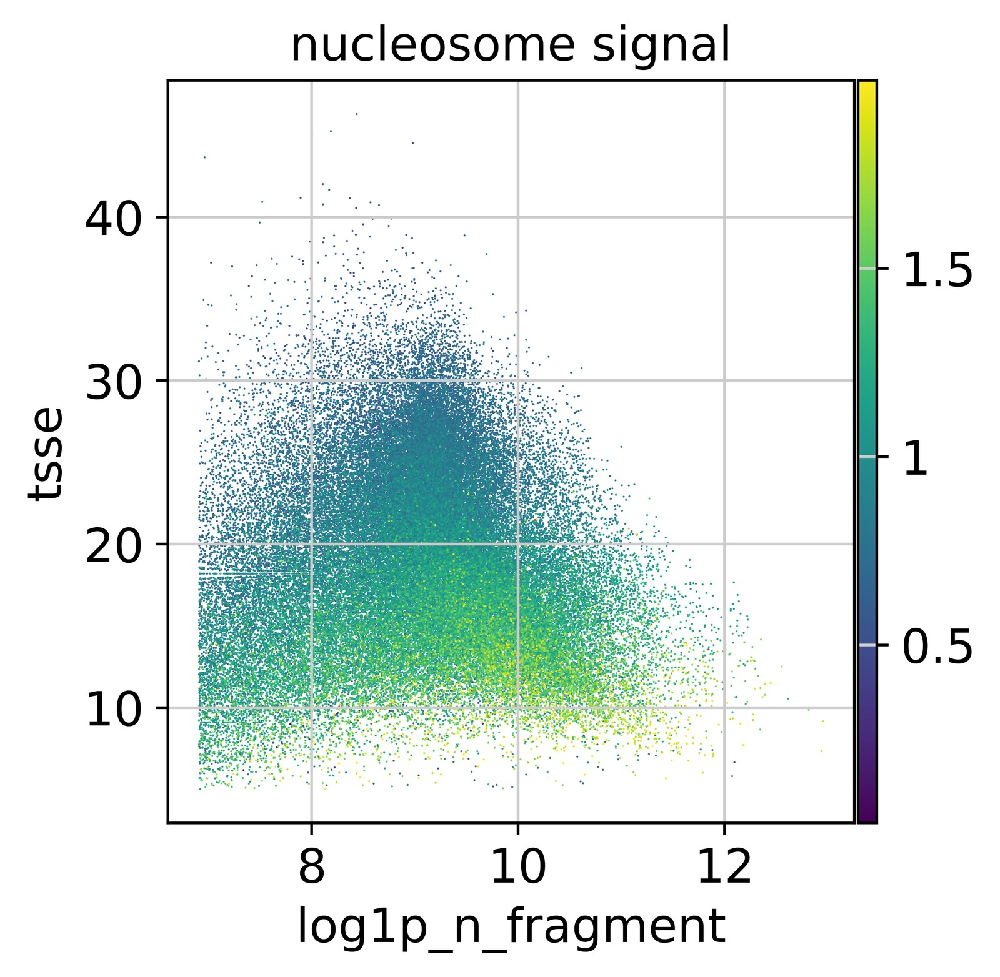

In [28]:
sc.pl.scatter(adata, "log1p_n_fragment", "tsse", color="nucleosome_signal")

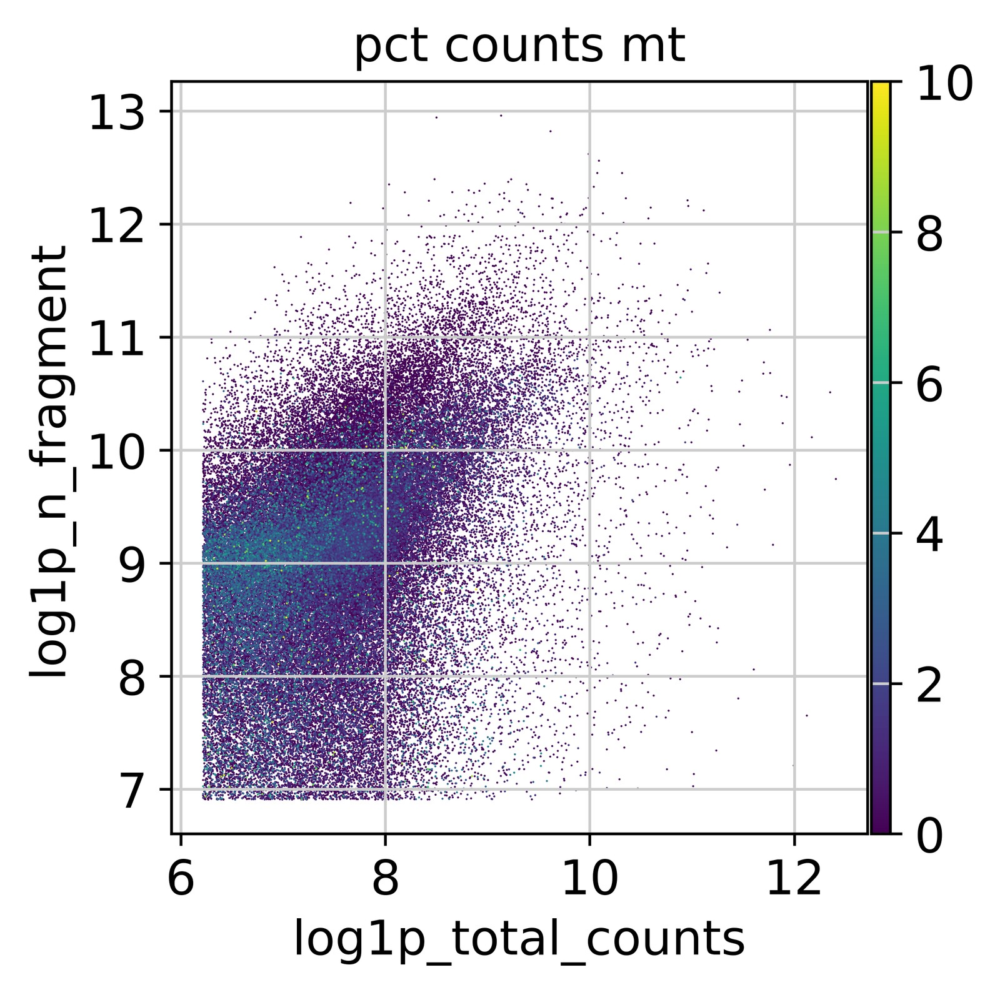

In [29]:
sc.pl.scatter(adata, "log1p_total_counts", "log1p_n_fragment", color="pct_counts_mt")

In [30]:
normalise_and_cluster(adata)

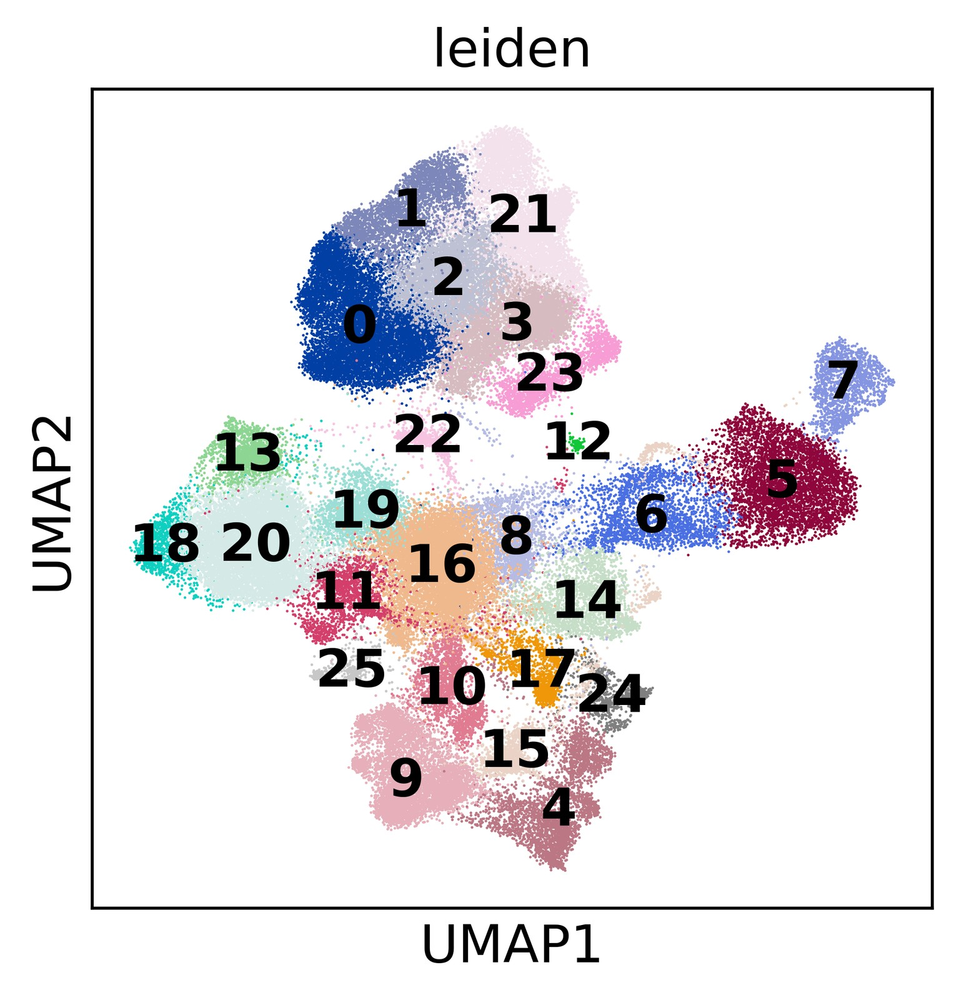

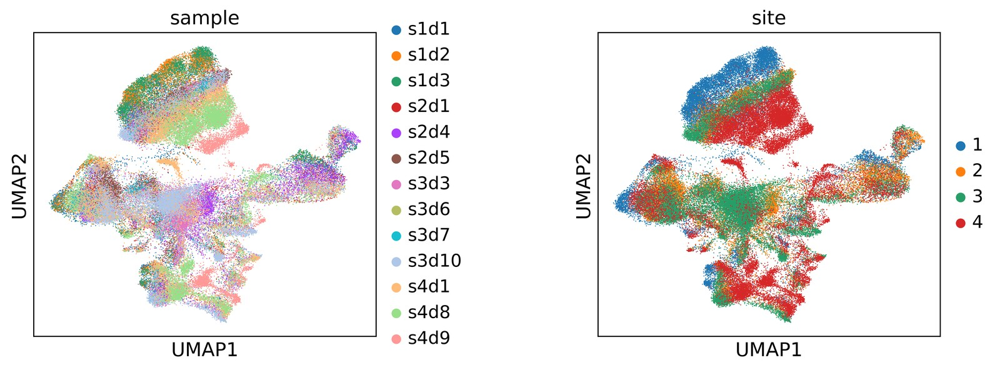

In [31]:
sc.pl.umap(adata, color="leiden", legend_loc="on data", size=2)
sc.pl.umap(adata, color=["sample", "site"], wspace=0.5, size=2)

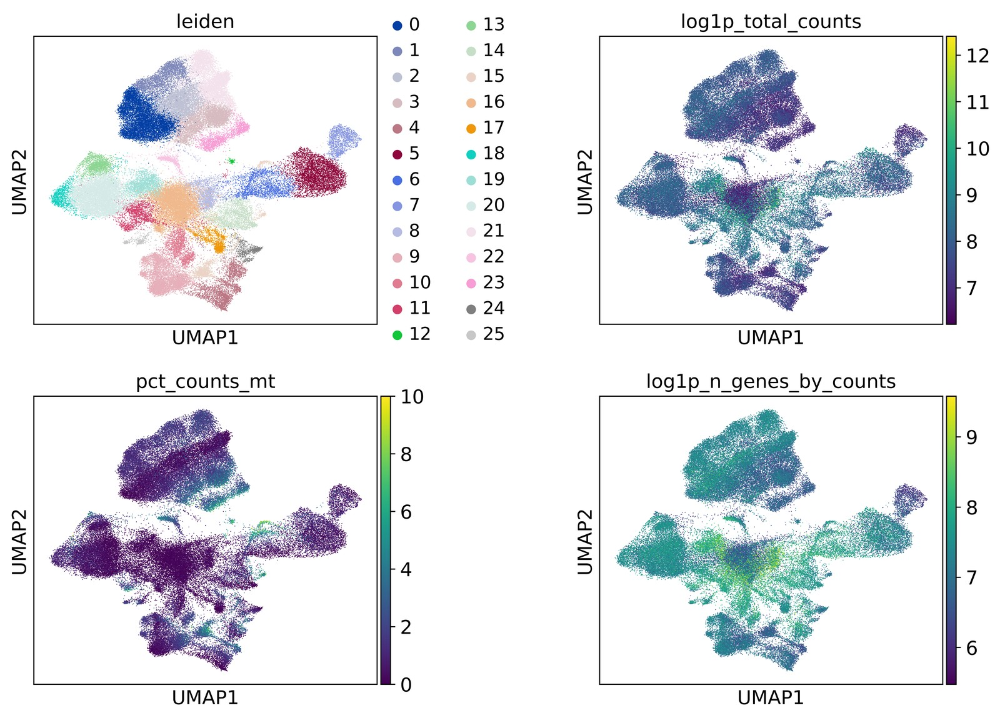

In [32]:
sc.pl.umap(
    adata,
    color=["leiden", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts"],
    wspace=0.5,
    ncols=2,
)

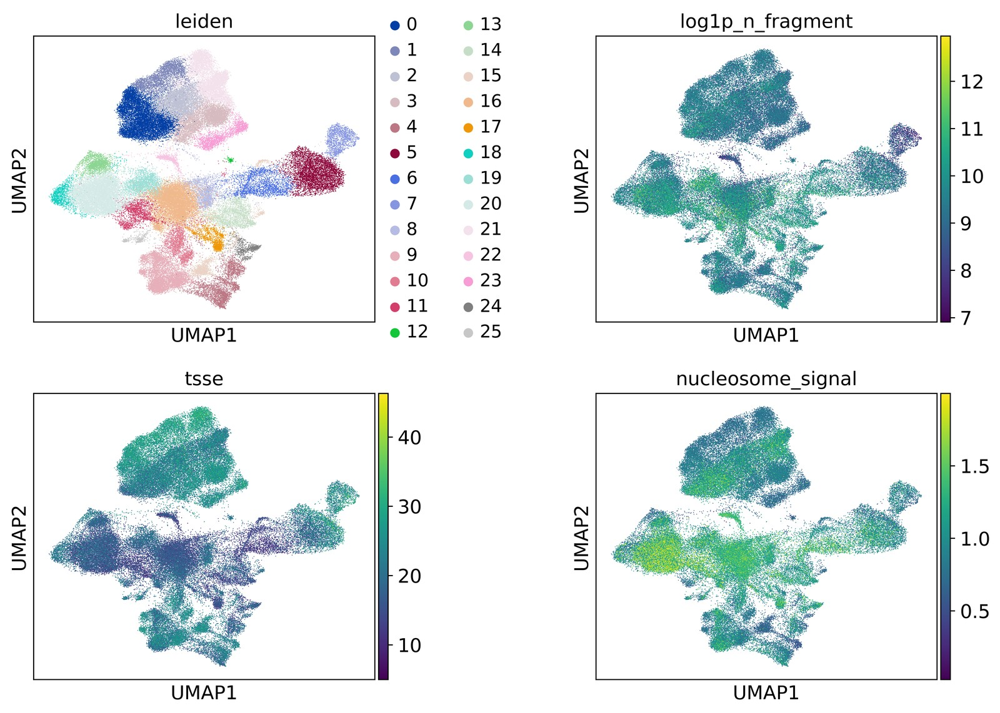

In [33]:
sc.pl.umap(
    adata,
    color=["leiden", "log1p_n_fragment", "tsse", "nucleosome_signal"],
    wspace=0.5,
    ncols=2,
)

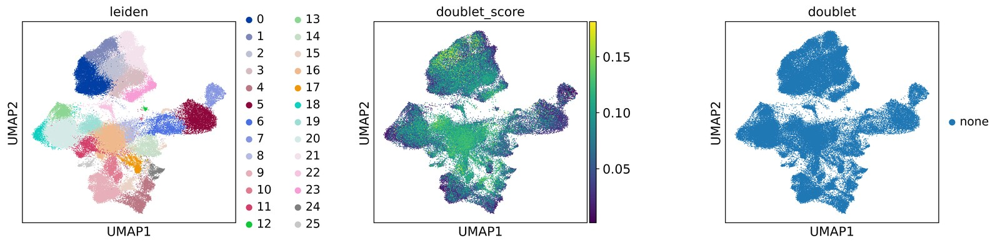

In [34]:
sc.pl.umap(
    adata,
    color=["leiden", "doublet_score", "doublet"],
    wspace=0.5,
    size=3,
)

### Final filtering

The thresholds from the first filtering, plus upper limits on RNA counts and ATAC fragments to remove
remaining potential doublets. Preview, adjust, then apply.

In [35]:
checks = pd.DataFrame({
    "RNA: genes >= 100": adata.obs["n_genes_by_counts"] >= 100,
    "RNA: counts 500-25,000": adata.obs["total_counts"].between(500, 25_000),
    "RNA: mito <= 10%": adata.obs["pct_counts_mt"] <= 10,
    "ATAC: fragments <= 100,000": adata.obs["n_fragment"] <= 100_000,
    "ATAC: TSSE >= 5": adata.obs["tsse"] >= 5,
    "ATAC: nucleosome signal < 2": adata.obs["nucleosome_signal"] < 2,
})

summary = pd.DataFrame({
    "fail": (~checks).sum(),
    "fail only this check": {c: (~checks[c] & checks.drop(columns=c).all(axis=1)).sum() for c in checks},
})
print(summary.to_string())

keep = checks.all(axis=1)
print(f"\nWould remove {(~keep).sum()} of {len(keep)} cells ({(~keep).mean():.1%}), keeping {keep.sum()}")

adata.obs["qc"] = pd.Categorical(np.where(keep, "keep", "remove"))
print(pd.crosstab(adata.obs["sample"], adata.obs["qc"]).to_string())
print(pd.crosstab(adata.obs["site"], adata.obs["qc"]).to_string())

                             fail  fail only this check
RNA: genes >= 100               0                     0
RNA: counts 500-25,000        420                   401
RNA: mito <= 10%                0                     0
ATAC: fragments <= 100,000    331                   312
ATAC: TSSE >= 5                 0                     0
ATAC: nucleosome signal < 2     0                     0

Would remove 732 of 86636 cells (0.8%), keeping 85904
qc       keep  remove
sample               
s1d1     6961      11
s1d2     6781       7
s1d3     4715      14
s2d1     4598      66
s2d4     7204     134
s2d5     5993      64
s3d3     9900      76
s3d6     1926      48
s3d7     1941     253
s3d10   11457      27
s4d1     9404      26
s4d8    10131       3
s4d9     4893       3
qc     keep  remove
site               
1     18457      32
2     17795     264
3     25224     404
4     24428      32


In [36]:
# share of each cluster failing each check
by_cluster = (~checks).groupby(adata.obs["leiden"], observed=True).mean().round(2)
by_cluster.insert(0, "cells", adata.obs["leiden"].value_counts())
by_cluster

,cells,RNA: genes >= 100,"RNA: counts 500-25,000",RNA: mito <= 10%,"ATAC: fragments <= 100,000",ATAC: TSSE >= 5,ATAC: nucleosome signal < 2
leiden,,,,,,,
0,9490,0.0,0.00,0.0,0.00,0.0,0.0
1,3312,0.0,0.00,0.0,0.00,0.0,0.0
2,4819,0.0,0.00,0.0,0.00,0.0,0.0
3,5363,0.0,0.00,0.0,0.00,0.0,0.0
4,3237,0.0,0.00,0.0,0.00,0.0,0.0
5,4610,0.0,0.00,0.0,0.00,0.0,0.0
6,2254,0.0,0.00,0.0,0.00,0.0,0.0
7,1549,0.0,0.00,0.0,0.00,0.0,0.0
8,2031,0.0,0.07,0.0,0.01,0.0,0.0


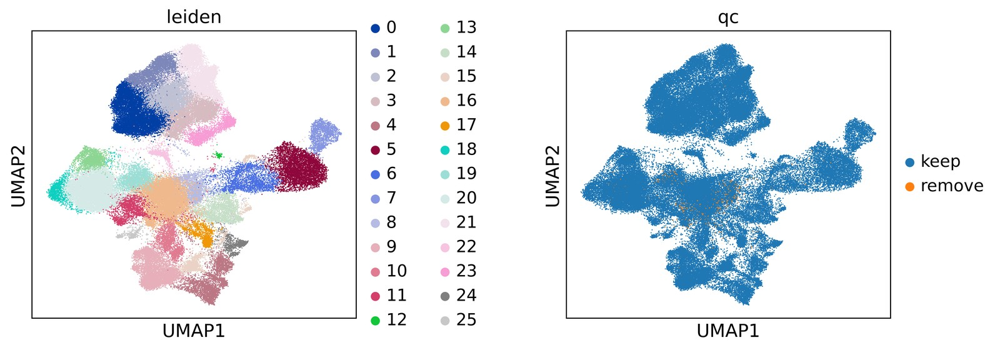

In [37]:
sc.pl.umap(adata, color=["leiden", "qc"], wspace=0.5, size=3)

### Apply the final filter

Removes the cells failing any check, then genes detected in fewer than 3 of the remaining cells, so the
saved gene set is defined by the final cells.

In [38]:
adata = adata[keep].copy()
sc.pp.filter_genes(adata, min_cells=3)
adata

AnnData object with n_obs × n_vars = 85904 × 32475
    obs: 'sample', 'site', 'donor', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_fragment', 'tsse', 'nucleosome_signal', 'log1p_n_fragment', 'n_genes', 'doublet_score', 'predicted_doublet', 'amulet_q', 'amulet_multiplet', 'doublet', 'leiden', 'qc'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'scrublet', 'hvg', 'pca', 'neighbors', 'umap', 'leiden', 'leide

## Final clustering

Normalization, feature selection, dimensionality reduction, neighbours, UMAP and clustering as in the
tutorial, now on the filtered cells, using the same function as the exploratory clustering.

In [39]:
normalise_and_cluster(adata)

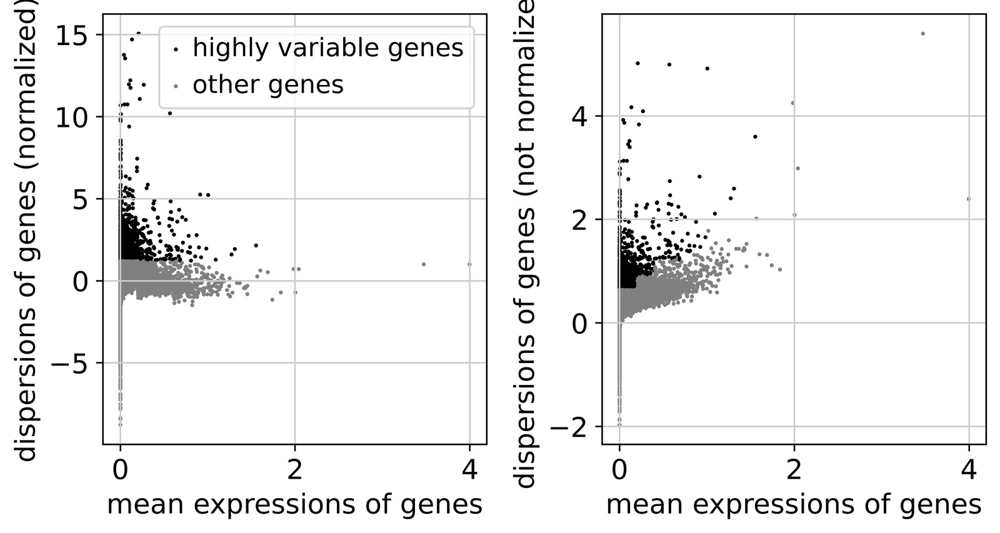

In [40]:
sc.pl.highly_variable_genes(adata)

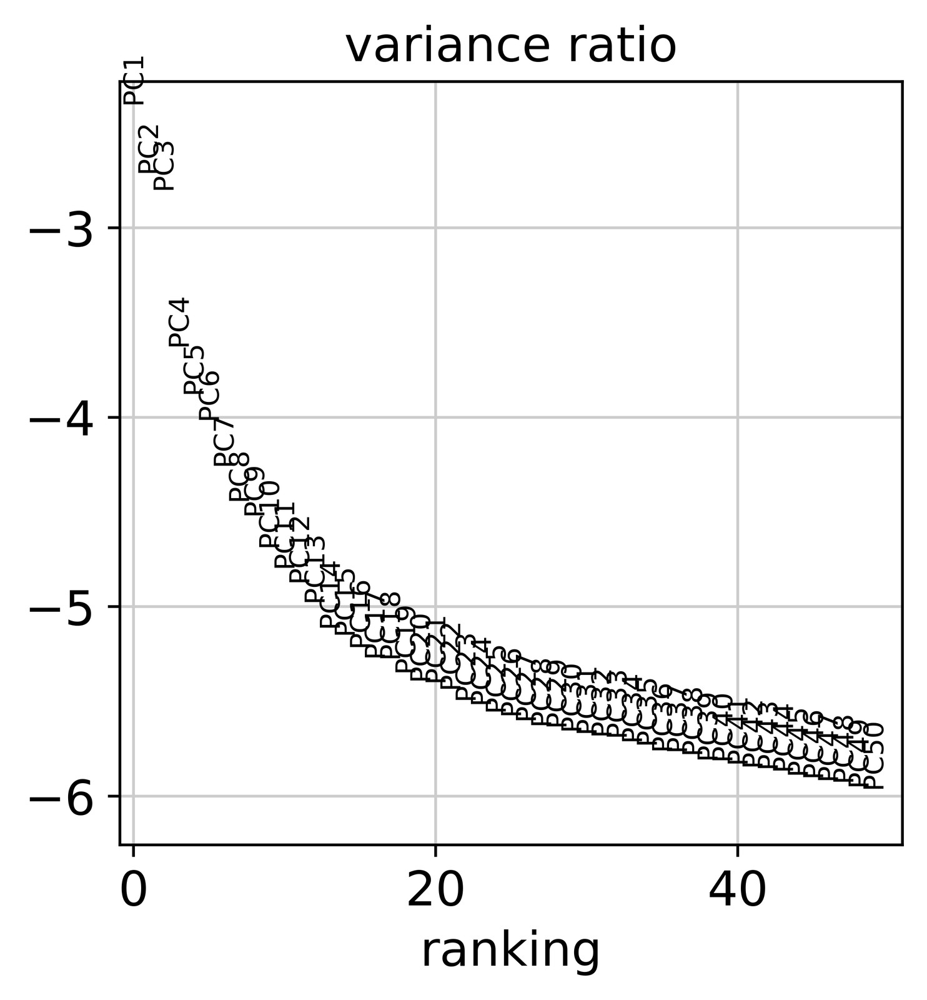

In [41]:
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

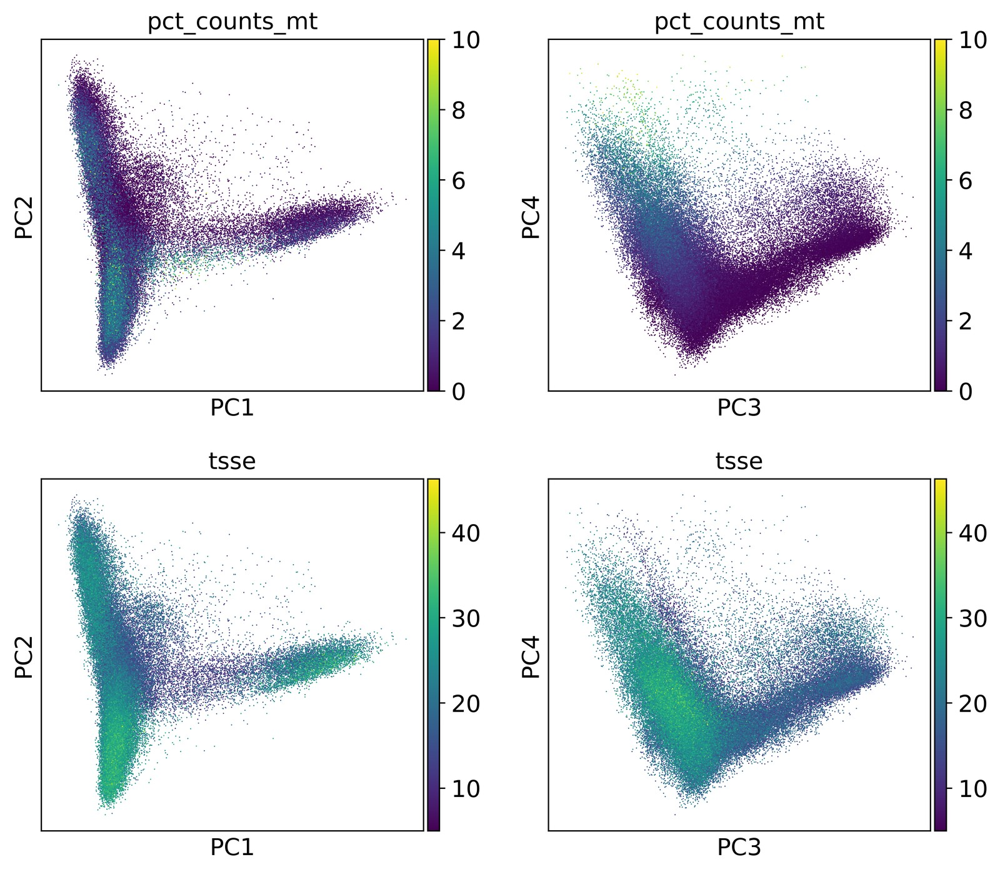

In [42]:
sc.pl.pca(
    adata,
    color=["pct_counts_mt", "pct_counts_mt", "tsse", "tsse"],
    dimensions=[(0, 1), (2, 3), (0, 1), (2, 3)],
    ncols=2,
    size=2,
)

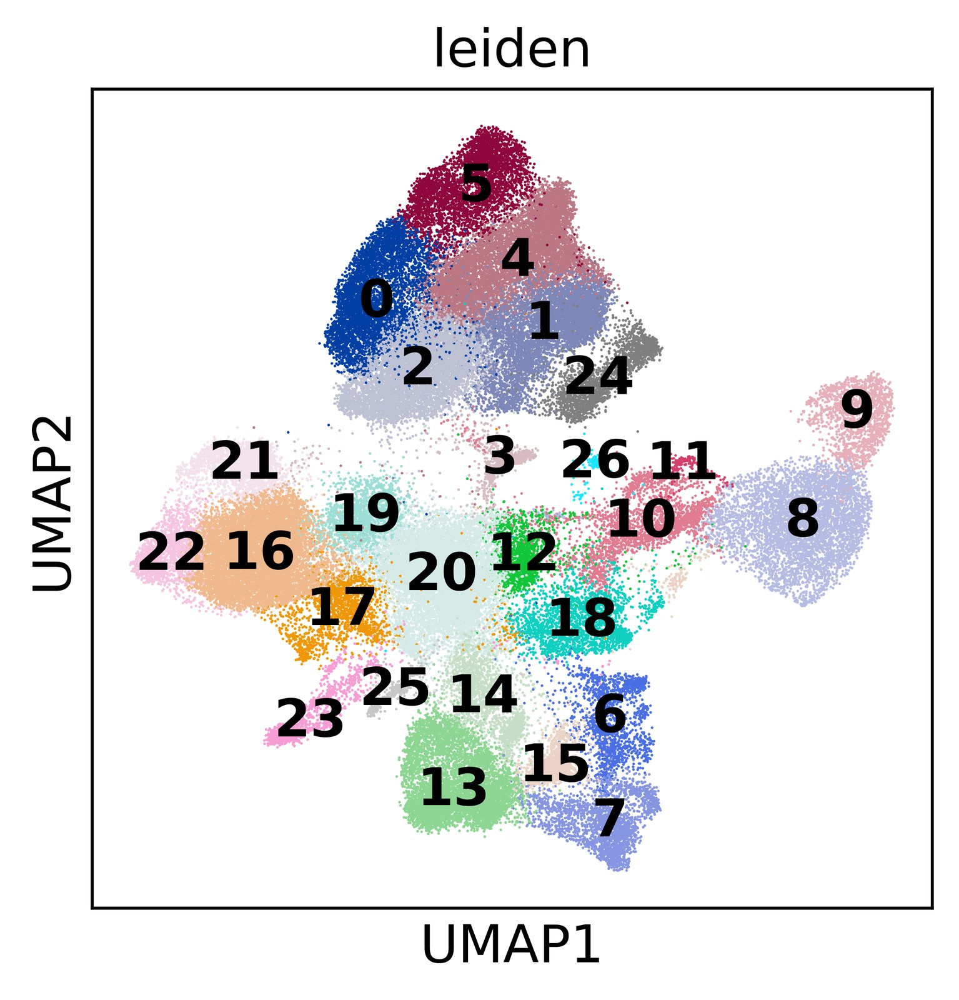

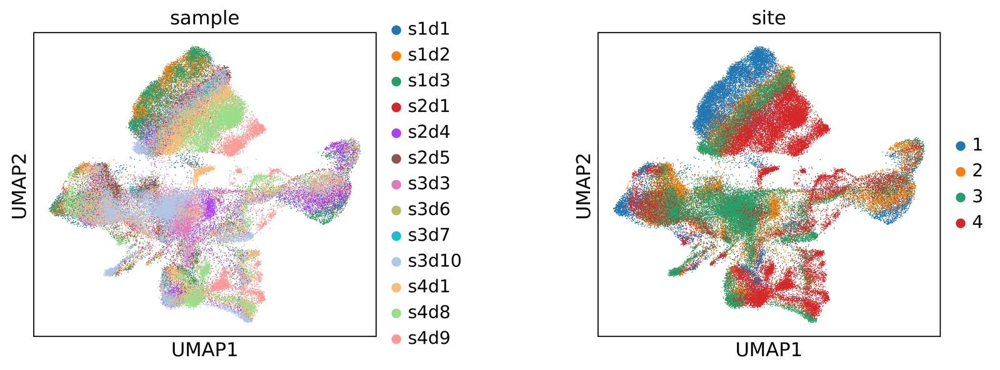

In [43]:
sc.pl.umap(adata, color="leiden", legend_loc="on data", size=2)
sc.pl.umap(adata, color=["sample", "site"], wspace=0.5, size=2)

Final check: no cluster should still be defined by a QC metric or doublet score. If one is, go back to
**Final filtering**.

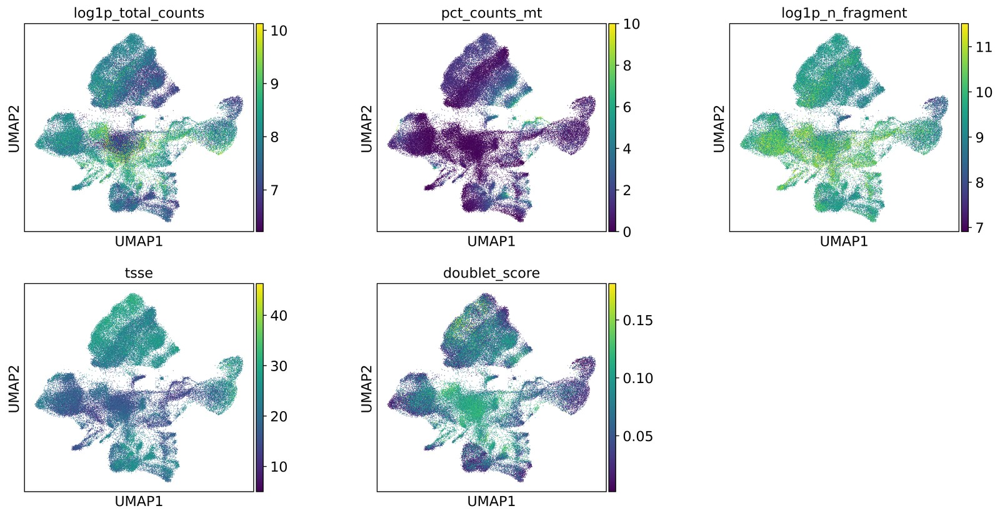

In [44]:
sc.pl.umap(
    adata,
    color=["log1p_total_counts", "pct_counts_mt", "log1p_n_fragment", "tsse", "doublet_score"],
    ncols=3,
    wspace=0.4,
)

## Cell-type annotation with Azimuth

[Azimuth](https://azimuth.hubmapconsortium.org/), run from Python with
[azimuthpy](https://github.com/KalinNonchev/azimuthpy), maps each cell onto an annotated reference and
transfers its labels. Here the reference is the Azimuth **human PBMC** reference (Hao et al. 2021), at its `celltype.l1` level (broad types: B, CD4 T, CD8 T, other T, NK, Mono, DC, other). The reference also has the finer `celltype.l2` and `celltype.l3` levels, which Azimuth predicts too.

Azimuth normalises the raw counts itself, so it is given `adata.layers["counts"]` of the final cells. It is the slowest step (single-threaded R, hours on this many cells), so it runs as a batch job, `jobs/08_azimuth.sbatch`, rather than in this notebook: the next cell saves the final cells, the job annotates them, and the cell after that loads its results.
It adds to `adata.obs`, per cell:

- `predicted.celltype.l1`: the predicted label.
- `predicted.celltype.l1.score`: confidence in that label, from 0 to 1.
- `mapping.score`: how well the cell is represented in the reference, from 0 to 1. Low values mean
  the cell doesn't resemble anything in the reference.

and the cells' positions on the reference UMAP in `adata.obsm["ref.umap"]`. The reference files were
downloaded by `jobs/05_create_env_azimuth.sbatch`.

Bone marrow has populations PBMC does not, such as HSPCs, erythroid and myeloid progenitors, and plasma cells. The
PBMC reference has no matching classes for them, so expect them to map to `other` or to the nearest blood type,
with lower scores. Downstream comparisons with PBMC use only the six mature types (Mono, CD4 T, CD8 T, B, NK, DC).

In [45]:
# the final cells, so the session can end while the job runs
adata.layers.pop("raw_counts", None)  # left by an earlier in-notebook Azimuth call, if any
checkpoint = work_dir / "clustered.h5ad"
adata.write_h5ad(checkpoint)
print(f"wrote {checkpoint}: {adata.n_obs:,} cells x {adata.n_vars:,} genes")
print(f"now submit: cd {ROOT} && sbatch jobs/08_azimuth.sbatch")

wrote /gpfs/scratch/qp252877/multiome_data/processed/bmmc_all/clustered.h5ad: 85,904 cells x 32,475 genes
now submit: cd /data/home/qp252877/multiome && sbatch jobs/09_azimuth.sbatch


Submit the job from the repo root (array index 3 = `bmmc_all`, the default):

```
sbatch jobs/08_azimuth.sbatch
```

It reads `clustered.h5ad` and writes `azimuth.h5ad` (Azimuth's columns and `ref.umap` for the same cells, in the same
order) to `work_dir`; the log is `logs/azimuth.<job>_3.o`. This session can be closed while it runs. When it has
finished, run the first code cell (imports and paths), then continue from the next cell.

In [46]:
adata = sc.read_h5ad(work_dir / "clustered.h5ad")
azimuth = sc.read_h5ad(work_dir / "azimuth.h5ad")
assert azimuth.obs_names.equals(adata.obs_names), "azimuth.h5ad is for different cells: rerun the save cell and the job"
adata.obs = adata.obs.join(azimuth.obs)
adata.obsm["ref.umap"] = azimuth.obsm["ref.umap"]
adata

AnnData object with n_obs × n_vars = 85904 × 32475
    obs: 'sample', 'site', 'donor', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_fragment', 'tsse', 'nucleosome_signal', 'log1p_n_fragment', 'n_genes', 'doublet_score', 'predicted_doublet', 'amulet_q', 'amulet_multiplet', 'doublet', 'leiden', 'qc', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', '

In [47]:
label = "predicted.celltype.l1"
adata.obs[label] = adata.obs[label].astype("category")

adata.obs.groupby(label, observed=True).agg(
    cells=(label, "size"),
    median_prediction_score=(f"{label}.score", "median"),
    median_mapping_score=("mapping.score", "median"),
).round(2)

,cells,median_prediction_score,median_mapping_score
predicted.celltype.l1,,,
B,11519,1.00,0.44
CD4 T,16935,0.67,0.37
CD8 T,13371,0.68,0.37
DC,1487,0.92,0.46
Mono,14202,0.82,0.35
NK,9055,0.72,0.37
other,14853,0.62,0.31
other T,4482,0.52,0.42


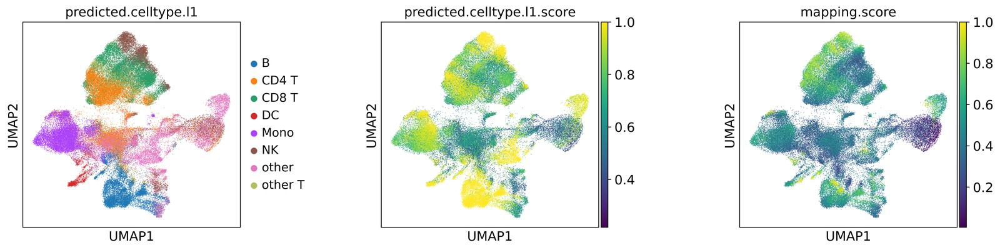

In [48]:
sc.pl.umap(adata, color=[label, f"{label}.score", "mapping.score"], wspace=0.5)

The same cells placed on the reference's UMAP:

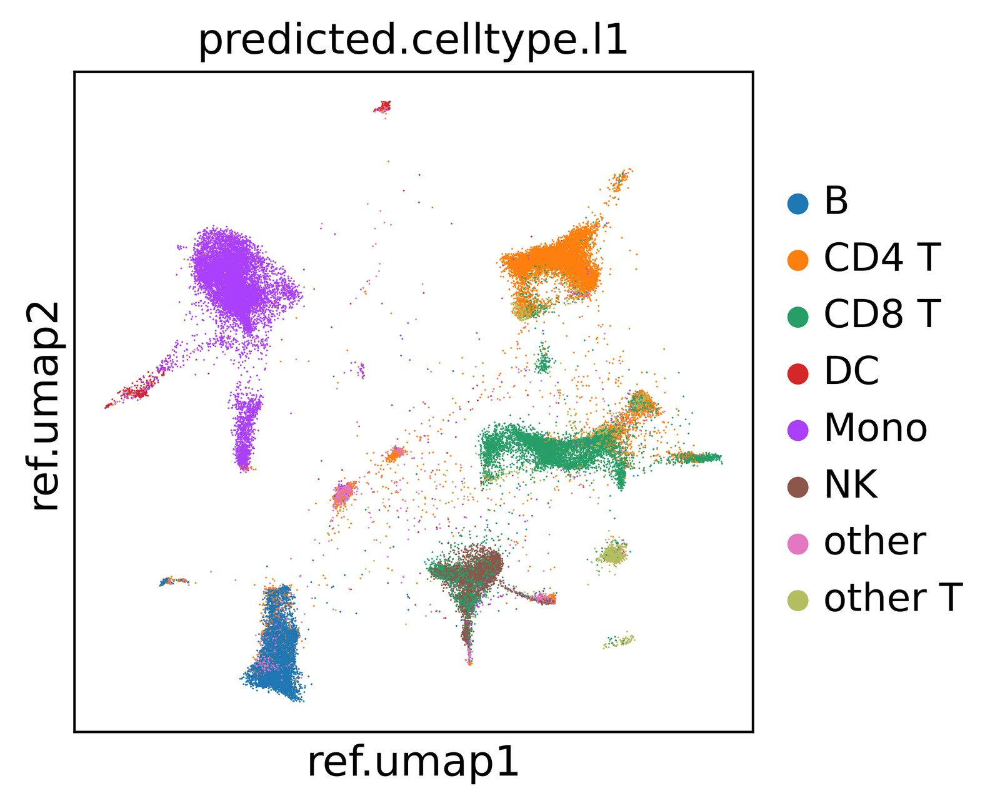

In [49]:
sc.pl.embedding(adata, basis="ref.umap", color=label)

Predicted labels per Leiden cluster. A cluster split across several labels, or a label spread across
many clusters, is worth checking against marker genes.

In [50]:
pd.crosstab(adata.obs["leiden"], adata.obs[label])

predicted.celltype.l1,B,CD4 T,CD8 T,DC,Mono,NK,other,other T
leiden,,,,,,,,
0,0,2756,1672,1,1,16,11,792
1,0,862,4150,0,1,179,4,749
2,0,5350,1048,0,0,22,13,791
3,112,603,27,2,10,2,204,17
4,0,310,3700,0,0,2634,24,551
5,1,17,1665,0,0,2261,12,140
6,113,116,3,4,3,682,763,10
7,1437,56,1,0,1,6,815,4
8,12,686,1,1,0,1734,2438,7


### Assign cell types

`cell_type` is the Azimuth label, except that cells with a prediction score below `MIN_SCORE` are
labelled "low confidence". Choose `MIN_SCORE` from the score plots above.

In [51]:
MIN_SCORE = 0

confident = adata.obs[f"{label}.score"] >= MIN_SCORE
adata.obs["cell_type"] = adata.obs[label].astype(str).where(confident, "low confidence").astype("category")
adata.obs["cell_type"].value_counts()

cell_type
CD4 T      16935
other      14853
Mono       14202
CD8 T      13371
B          11519
NK          9055
other T     4482
DC          1487
Name: count, dtype: int64

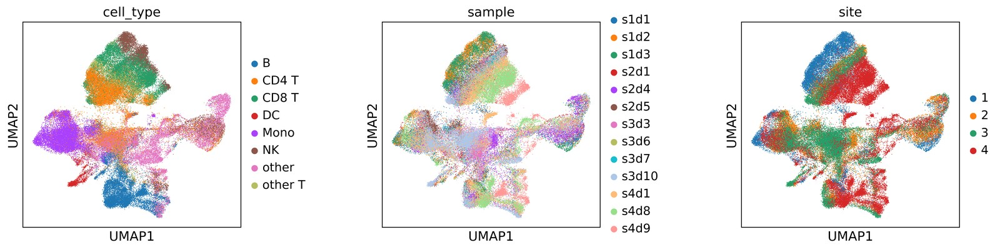

In [52]:
sc.pl.umap(adata, color=["cell_type", "sample", "site"], wspace=0.5, size=2)

## Highly variable gene flags

Two flags, one row per gene kept after filtering:

- `hvg_clustering`: the 2,000 genes used for PCA, neighbours and clustering above.
- `hvg_eval`: scanpy's default HVG selection (fixed mean and dispersion cut-offs, so the
  number varies by dataset), computed with `batch_key="sample"`: means
  and normalised dispersions are computed within each of the 13 samples and averaged, so genes that
  vary only between samples (immediate-early stress genes, donor HLA haplotypes) are not selected.
  PBMC and brain are single libraries and use no batch key. Ambient haemoglobin varies within every
  sample, so it still passes. Use this one to evaluate models.

Both are computed on the log-normalised expression of the final cells. Gene symbols can be
duplicated, so join on `gene_id` downstream.

In [54]:
# per-sample means and dispersions, averaged over the 13 samples; the batched result is sorted by gene name
hvg_defaults = sc.pp.highly_variable_genes(adata, batch_key="sample", inplace=False)
assert set(hvg_defaults.index) == set(adata.var_names)
adata.var["hvg_eval"] = hvg_defaults.loc[adata.var_names, "highly_variable"].to_numpy()

genes = pd.DataFrame({
    "gene_id": adata.var["gene_ids"],
    "n_cells": adata.var["n_cells"],
    "hvg_clustering": adata.var["highly_variable"],
    "hvg_eval": adata.var["hvg_eval"],
}).rename_axis("gene_symbol")
genes.to_csv(out_dir / "genes.tsv", sep="\t")
genes[["hvg_clustering", "hvg_eval"]].sum()

hvg_clustering    2000
hvg_eval          2796
dtype: int64

## Save

The final cells with QC metrics, doublet calls, sample, site, donor, clusters, Azimuth predictions and HVG flags. There is no
ATAC peak matrix for BMMC; ATAC analyses use the fragment files directly.

In [55]:
adata.write_h5ad(out_dir / "rna_annotated.h5ad")

## Check the saved files

Reads the saved files back and stops with an error if any check fails: the same cells as the final
`adata`, a cell-type label and scores for every cell, and both HVG flags for every gene,
matching `genes.tsv`.

In [56]:
# Read the saved files back and compare them with the final adata
rna_saved = sc.read_h5ad(out_dir / "rna_annotated.h5ad", backed="r")
genes_saved = pd.read_csv(out_dir / "genes.tsv", sep="\t", index_col="gene_symbol")

# cells: same cells as the final adata, in the same order, with a sample for each
assert rna_saved.shape == adata.shape, (rna_saved.shape, adata.shape)
assert (rna_saved.obs_names == adata.obs_names).all()
assert rna_saved.obs_names.is_unique
for col in ["sample", "site", "donor"]:
    assert rna_saved.obs[col].notna().all(), col

# cell-type labels: present for every cell
for col in ["cell_type", label, f"{label}.score", "mapping.score"]:
    assert col in rna_saved.obs and rna_saved.obs[col].notna().all(), col
assert "ref.umap" in rna_saved.obsm

# HVG flags: a True/False flag for every gene, and genes.tsv matches the h5ad
for col in ["highly_variable", "hvg_eval"]:
    assert rna_saved.var[col].dtype == bool, col
assert (genes_saved.index == rna_saved.var_names).all()
assert (genes_saved["hvg_clustering"].to_numpy() == rna_saved.var["highly_variable"].to_numpy()).all()
assert (genes_saved["hvg_eval"].to_numpy() == rna_saved.var["hvg_eval"].to_numpy()).all()
assert genes_saved["gene_id"].is_unique

print(f"{rna_saved.n_obs:,} cells, {rna_saved.n_vars:,} genes (RNA)")
print(f"HVGs: {int(genes_saved['hvg_clustering'].sum()):,} for clustering, "
      f"{int(genes_saved['hvg_eval'].sum()):,} for evaluation")
rna_saved.file.close()
pd.crosstab(rna_saved.obs["cell_type"], rna_saved.obs["sample"], margins=True)

85,904 cells, 32,475 genes (RNA)
HVGs: 2,000 for clustering, 2,796 for evaluation


sample,s1d1,s1d2,s1d3,s2d1,s2d4,s2d5,s3d3,s3d6,s3d7,s3d10,s4d1,s4d8,s4d9,All
cell_type,,,,,,,,,,,,,,
B,941,378,318,682,972,374,1333,116,251,931,1541,2134,1548,11519
CD4 T,1677,1409,989,722,1026,741,3116,266,207,2208,2524,1284,766,16935
CD8 T,914,1914,1248,250,187,987,855,322,200,715,1152,3766,861,13371
DC,103,102,67,117,74,89,127,53,59,532,93,55,16,1487
Mono,993,872,280,1623,1144,2696,1001,267,828,2698,1204,460,136,14202
NK,853,1264,822,559,919,875,568,239,170,841,709,640,596,9055
other,1240,332,513,538,2812,80,2017,344,161,3281,1733,1096,706,14853
other T,240,510,478,107,70,151,883,319,65,251,448,696,264,4482
All,6961,6781,4715,4598,7204,5993,9900,1926,1941,11457,9404,10131,4893,85904
